# 18. Buttresses

A cylinder cannot follow a flanged base: where a tropical tree flares into
buttresses, a circle fitted to a slice of the stem spans the gaps between the
flanges. `trees.detect_buttress` finds such bases and `qsm.buttress_mesh`
rebuilds them as a closed mesh, which `Buttress.fuse` joins to the cylinder
model of the stem above. The [QSM guide](../guide/qsm.md#buttresses) has the
details; this notebook runs them on real trees.

The data are two trees from the destructive-harvest data of Burt et al.
(2021), each cloud holding a single tree: one with a flanged base, kept whole
(46 m tall, thinned to 1 cm up to 6 m, where the buttress functions read the
points, and to 5 cm above), and one with a round stem, kept to its lowest 8 m.
Both are in a frame with the stem at the origin and its foot at z = 0, so that z
is the height above ground the functions take; `make_buttress_subset.py`
cuts them.

In [1]:
import tempfile
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.colors import ListedColormap, to_rgb
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
import sylva
from sylva import qsm, trees

DATA = Path("data")          # the two trees, cut by make_buttress_subset.py
tmp = Path(tempfile.mkdtemp())      # files written here are temporary
plt.style.use("sylva.mplstyle")     # shared figure style; C0 to C7 are the Okabe-Ito colours
GROUND, WOOD, LEAF, GRASS, CONTEXT = "#997A5C", "#4D2B12", "#009E73", "#E69F00", "0.8"   # the same in every notebook
DIVERGING = "RdBu_r"                # for signed differences, centred on zero
LABELS = ListedColormap(["#332288", "#88CCEE", "#44AA99", "#117733", "#999933", "#DDCC77",
                         "#CC6677", "#882255", "#AA4499"])   # tree ids and clusters: Paul Tol's muted set

In [2]:
def read_tree(name):
    tree = sylva.read(DATA / name)
    return tree.with_attrs(height=tree.z)       # z is already the height above ground in this frame


tree = read_tree("buttress_tree.laz")
round_tree = read_tree("round_tree.laz")
lo, hi = tree.bounds
print(tree)
print("extent of the flanged tree:", np.round(hi - lo, 1), "m")
print(round_tree)
near = np.hypot(tree.x, tree.y) < 2.5       # the points around the stem, for the slice plots

PointCloud(n=1,044,390, attrs=['classification', 'gps_time', 'height', 'intensity', 'number_of_returns', 'point_source_id', 'return_number', 'scan_angle', 'user_data'])
extent of the flanged tree: [24.6 26.  46.4] m
PointCloud(n=41,136, attrs=['classification', 'gps_time', 'height', 'intensity', 'number_of_returns', 'point_source_id', 'return_number', 'scan_angle', 'user_data'])


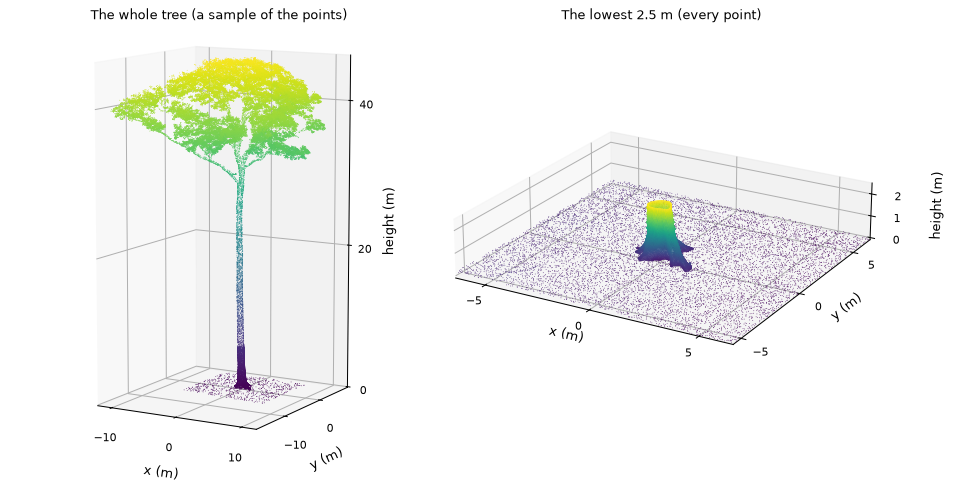

In [3]:
def frame(ax, vertices):
    """Axes limits and box proportions that match the data, with few ticks."""
    lo, hi = vertices.min(0), vertices.max(0)
    ax.set(xlim=(lo[0], hi[0]), ylim=(lo[1], hi[1]), zlim=(lo[2], hi[2]),
           xlabel="x (m)", ylabel="y (m)", zlabel="height (m)")
    ax.set_box_aspect(hi - lo)
    ax.locator_params(nbins=4)                       # the boxes can be narrow
    ax.zaxis.labelpad = 8


def draw_mesh(ax, vertices, faces, colour, azim, elev=22):
    """A triangle mesh with flat shading, lit from above and from one side."""
    tri = vertices[faces]
    normal = np.cross(tri[:, 1] - tri[:, 0], tri[:, 2] - tri[:, 0])
    normal /= np.linalg.norm(normal, axis=1, keepdims=True) + 1e-12
    sun = np.array([np.cos(np.radians(azim + 40)), np.sin(np.radians(azim + 40)), 1.0])
    shade = 0.35 + 0.65 * np.abs(normal @ sun) / np.linalg.norm(sun)
    ax.add_collection3d(Poly3DCollection(tri, facecolors=shade[:, None] * np.array(to_rgb(colour)), linewidths=0))
    ax.view_init(elev=elev, azim=azim)


rng = np.random.default_rng(0)
whole = tree[rng.choice(len(tree), 80_000, replace=False)]     # a sample, to keep the figure light
foot = tree[tree.z < 2.5]                                      # the base, at full density
fig = plt.figure(figsize=(10, 6))
for k, (cloud, title, view) in enumerate([(whole, "The whole tree (a sample of the points)", 10),
                                          (foot, "The lowest 2.5 m (every point)", 22)]):
    ax = fig.add_subplot(1, 2, k + 1, projection="3d")
    ax.scatter(cloud.x, cloud.y, cloud.z, s=0.4, c=cloud.z, cmap="viridis", linewidths=0, depthshade=False)
    frame(ax, cloud.xyz)
    ax.view_init(elev=view, azim=-60)
    ax.set_title(title)

The flanged tree's cloud also holds a sparse scatter of ground returns around
its foot. They are left in: `detect_buttress` reads only bark-like points and
`buttress_mesh` does not close ground into the solid. The slice plots below show
only the points within 2.5 m of the stem.

## Is the base buttressed?

`detect_buttress` looks only at bark-like points (locally planar, with a
near-horizontal normal) and asks two things: how much of the base a circle
explains compared with the stem higher up, and whether protrusions persist at
the same angles through the lowest metre. It finds the stem itself when it is
not told where it is.

In [4]:
b = trees.detect_buttress(tree)
r = trees.detect_buttress(round_tree)
for name, d in (("flanged", b), ("round", r)):
    print(f"{name:8s} buttressed: {str(d['buttressed']):5s} {d['ridges']} ridges; a circle explains "
          f"{d['base_circle_fit']:.0%} of the bark points below 1 m and {d['stem_circle_fit']:.0%} above 2 m")
print(f"the flanges of the first tree end {b['top']:.1f} m up; its round stem has a radius of {b['stem_radius']:.2f} m")

flanged  buttressed: True  4 ridges; a circle explains 16% of the bark points below 1 m and 62% above 2 m
round    buttressed: False 0 ridges; a circle explains 72% of the bark points below 1 m and 100% above 2 m
the flanges of the first tree end 1.7 m up; its round stem has a radius of 0.45 m


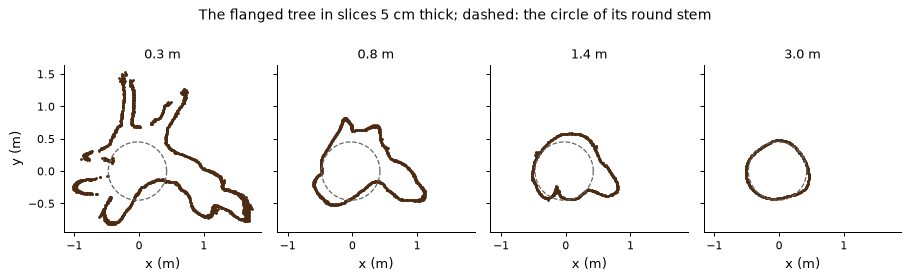

In [5]:
cx, cy = b["centre"]
theta = np.linspace(0, 2 * np.pi, 200)
fig, axes = plt.subplots(1, 4, figsize=(10, 3), sharex=True, sharey=True)
for ax, z in zip(axes, [0.3, 0.8, 1.4, 3.0]):
    s = (np.abs(tree.z - z) < 0.025) & near
    ax.scatter(tree.x[s], tree.y[s], s=1.5, c=WOOD)
    ax.plot(cx + b["stem_radius"] * np.cos(theta), cy + b["stem_radius"] * np.sin(theta), "--", c="0.4", lw=1)
    ax.set(title=f"{z} m", aspect="equal", xlabel="x (m)")
axes[0].set_ylabel("y (m)")
fig.suptitle("The flanged tree in slices 5 cm thick; dashed: the circle of its round stem");

Near the ground the section of the first tree is a star of flanges reaching
1.7 m from the stem axis, and the dashed circle of its round stem explains
little of it. The flanges merge into the trunk as the section rises, and by 3 m
it is round. The second tree has no flanges: a circle explains 72 % of its
base, so `detect_buttress` leaves it to the cylinder model.

## The base as a mesh

`buttress_mesh` rasterises thin slices of the points, closes the gaps that
occlusion leaves in the bark, and builds the sections from the top down, so
that each one contains the one above it. The stacked sections become a
watertight surface.

In [6]:
base = qsm.buttress_mesh(tree, b["centre"], top=b["top"])
print(f"{base.volume:.2f} m3 below {base.top:.1f} m in {len(base.vertices):,} vertices; "
      f"the outline was open (bark unseen) in {base.open.sum()} of {len(base.open)} slices")

2.75 m3 below 1.7 m in 31,062 vertices; the outline was open (bark unseen) in 1 of 34 slices


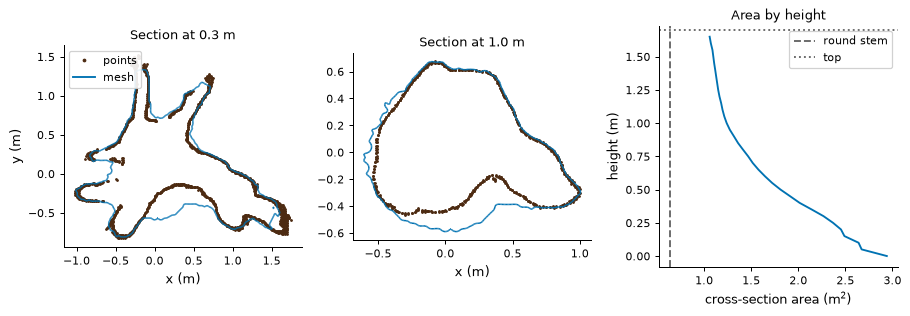

In [7]:
def section(mesh, z):
    """The segments where a mesh crosses the plane at height z, as an (n, 2, 2) array of xy."""
    v, f = mesh.vertices, mesh.faces
    d = v[f, 2] - z                                   # height of each corner above the plane
    found = []
    for i, j in ((0, 1), (1, 2), (2, 0)):             # a triangle that crosses the plane cuts two of its edges
        cut = d[:, i] * d[:, j] < 0
        t = d[cut, i] / (d[cut, i] - d[cut, j])
        a, c = v[f[cut, i], :2], v[f[cut, j], :2]
        found.append((np.flatnonzero(cut), a + t[:, None] * (c - a)))
    face = np.concatenate([i for i, _ in found])
    pts = np.concatenate([p for _, p in found])[np.argsort(face, kind="stable")]
    return pts.reshape(-1, 2, 2)


fig, ax = plt.subplots(1, 3, figsize=(10, 3.4))
for a, z in zip(ax[:2], [0.3, 1.0]):
    s = (np.abs(tree.z - z) < 0.025) & near
    a.scatter(tree.x[s], tree.y[s], s=1.5, c=WOOD)
    a.add_collection(LineCollection(section(base, z), colors="C0", linewidths=1.2))
    a.set(title=f"Section at {z} m", aspect="equal", xlabel="x (m)")
    a.autoscale()
ax[0].set_ylabel("y (m)")
ax[0].plot([], [], c=WOOD, marker=".", ls="", label="points")
ax[0].plot([], [], c="C0", label="mesh")
ax[0].legend(loc="upper left")
ax[2].plot(base.areas, base.heights, c="C0")
ax[2].axvline(np.pi * b["stem_radius"] ** 2, ls="--", c="0.4", label="round stem")
ax[2].axhline(base.top, ls=":", c="0.4", label="top")
ax[2].set(xlabel="cross-section area (m$^2$)", ylabel="height (m)", title="Area by height")
ax[2].legend();

The mesh follows the flanges and the notches between them, and the
cross-section area falls from 3.0 m$^2$ at the ground to 1.1 m$^2$ at the top.
That is still above the 0.6 m$^2$ of the round stem, because the section is not
yet round there (see the 1.4 m slice above).

The mesh can only follow what was scanned. Where the bark is not seen to the
end of a notch between two flanges, the outline closes it, so it can run a
little outside the points, as along the lower edge of the 1 m section.

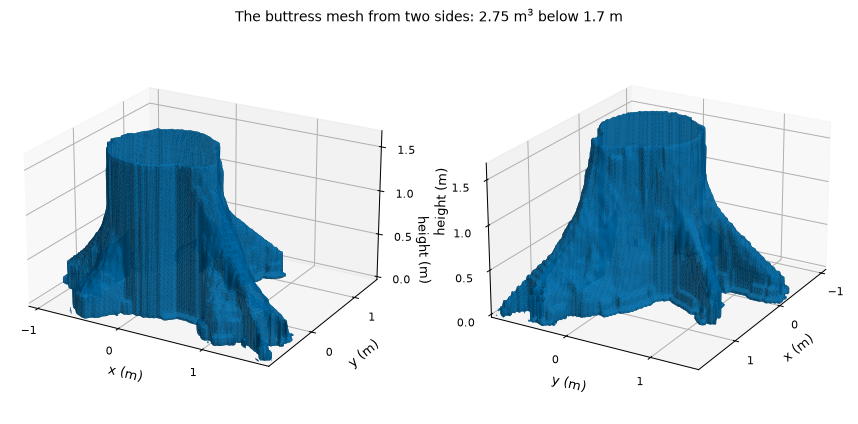

In [8]:
fig = plt.figure(figsize=(10, 4.6))
for k, azim in enumerate([-60, 30]):
    ax = fig.add_subplot(1, 2, k + 1, projection="3d")
    draw_mesh(ax, base.vertices, base.faces, "C0", azim)
    frame(ax, base.vertices)
fig.suptitle(f"The buttress mesh from two sides: {base.volume:.2f} m$^3$ below {base.top:.1f} m");

## Against a cylinder model

A cylinder model fitted from the ground up has to cover the base with circles.
The volume below the top of the buttress, and the DBH at 1.3 m (which on this
tree still falls inside the flanges), show what that costs. There is no
measured volume for these trees here: the [QSM guide](../guide/qsm.md#buttresses)
and the [benchmark](../benchmarks/qsm.md) score buttress meshes against felled
trees.

In [9]:
wood = qsm.wood_points(tree)                                                         # leaves and the litter around the base left out
plain = qsm.build_qsm(wood, base_xy=b["centre"])                                    # cylinders from the ground up
stem = qsm.build_qsm(wood[wood.attrs["height"] > base.top], base_xy=b["centre"])   # the stem and crown above the flanges
cyl_below = plain.total_volume - plain.volume_above(base.top_z)
print(f"DBH at 1.3 m: {plain.dbh:.2f} m from cylinders fitted from the ground, {stem.dbh:.2f} m on the round stem")
print(f"wood below {base.top:.1f} m: {cyl_below:.2f} m3 from the cylinders, {base.volume:.2f} m3 from the mesh "
      f"({base.volume / cyl_below - 1:+.0%})")
s = stem.summary()
print(f"the model above: {s['n_cylinders']:,} cylinders, {s['stem_volume_m3']:.1f} m3 of stem and "
      f"{s['branch_volume_m3']:.1f} m3 of branches, up to order {s['max_branch_order']}")

DBH at 1.3 m: 1.07 m from cylinders fitted from the ground, 0.92 m on the round stem
wood below 1.7 m: 2.01 m3 from the cylinders, 2.75 m3 from the mesh (+37%)
the model above: 15,323 cylinders, 14.9 m3 of stem and 7.5 m3 of branches, up to order 7


The circles cannot follow the flanges, so the base is mis-sized and the DBH
taken at 1.3 m is inflated, whichever way the volume goes. On the 15 buttressed
trees of the harvest benchmark the cylinder model alone is 10 % low in volume
against the felled trees, and 2 % high with the mesh below the top (see the
guide).

## One mesh of the whole tree

`Buttress.fuse` cuts the cylinder model at the top of the buttress and puts both
surfaces in one object. The buttress replaces the wood below its top, so nothing
is counted twice and the volume is the one `total_volume` reports. The two parts
stay watertight and labelled (`part` per face). Fewer `sides` per tube keep the
mesh light for a tree with this many branches.

In [10]:
fused = base.fuse(stem, sides=8)
print(f"fused: {fused.volume:.1f} m3 = {fused.buttress_volume:.2f} m3 buttress + {fused.wood_volume:.1f} m3 cylinders above it, "
      f"{len(fused.faces):,} faces")
assert abs(fused.volume - base.total_volume(stem)) < 1e-9
fused.to_obj(tmp / "tree.obj")        # objects "buttress" and "wood"
fused.to_ply(tmp / "tree.ply")        # one mesh, the base in bark brown
print({f.name: f"{f.stat().st_size / 1e6:.0f} MB" for f in sorted(tmp.iterdir())})

fused: 25.1 m3 = 2.75 m3 buttress + 22.4 m3 cylinders above it, 348,872 faces
{'tree.obj': '12 MB', 'tree.ply': '10 MB'}


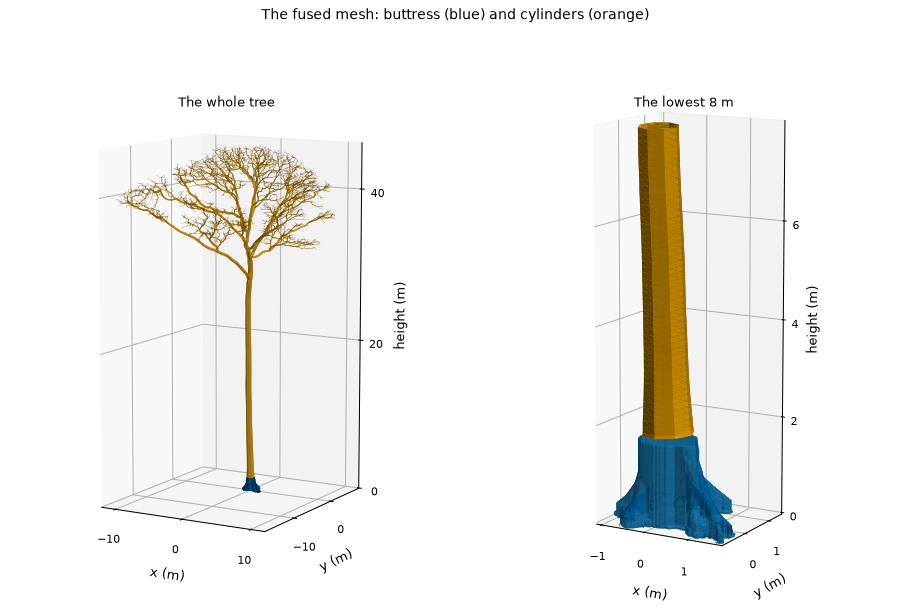

In [11]:
fig = plt.figure(figsize=(10, 7))
centroid_z = fused.vertices[fused.faces, 2].mean(axis=1)
for k, (title, below, azim, elev) in enumerate([("The whole tree", np.inf, -60, 10),
                                                ("The lowest 8 m", 8.0, -60, 12)]):
    ax = fig.add_subplot(1, 2, k + 1, projection="3d")
    for part, colour in ((0, "C0"), (1, "C1")):             # the buttress, then the cylinders above it
        faces = fused.faces[(fused.part == part) & (centroid_z < below)]
        draw_mesh(ax, fused.vertices, faces, colour, azim, elev)
    frame(ax, fused.vertices[fused.vertices[:, 2] < below])
    ax.set_title(title)
fig.suptitle("The fused mesh: buttress (blue) and cylinders (orange)");

On a real plot, run `detect_buttress` on each segmented tree and mesh the
ones it flags; `qsm.build_plot(..., buttress=True)` does both for every tree
and `plot.write_meshes` writes one fused surface per tree.